(sec-11-3)=
# 11.3 ECG Data in Python: PhysioNet Records, Annotations and Plots

Most of the ECGs in this book come from PhysioNet, the open archive of physiological recordings maintained at MIT {cite:p}`goldberger2000`. Its oldest and most heavily used collection is the MIT-BIH Arrhythmia Database: 48 half-hour excerpts of two-channel ambulatory recordings from 47 subjects, digitized at 360 Hz with 11-bit resolution over a 10 mV range, in which two or more cardiologists independently labeled every beat {cite:p}`moody2001`. For more than forty years, QRS detectors and arrhythmia classifiers have been tested on these files, and the ones we will build in Chapter 19 are no exception.

A record arrives as three small files: a text header, a binary signal file and a binary annotation file. The `wfdb` Python package reads all three in a line each, which is convenient but also makes it easy to use the data without understanding them. In my experience most mistakes with these databases come from the files rather than the algorithms: a beat label mistaken for an R-peak position, a rhythm label read as a beat label, an artifact annotation counted as a heartbeat, or a heart rate averaged in a way that quietly adds ten beats per minute.

This section is therefore a practical walkthrough. We read a header field by field, decode the binary signal format by hand and check it against the library, separate beat annotations from the other kinds, reconstruct rhythm episodes, draw an ECG on the standard paper grid, and compute the heart rate over a whole record. Section 1.4 introduced the general tools; here everything is specific to the ECG. The hardware that produced these numbers was the subject of [Section 11.2](02_recording_the_ecg.ipynb).

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

DATA = "../data/mitdb"
RECORDS = ["100", "105", "106", "119", "203", "208"]

(sec-11-3-1)=
## 11.3.1 The Files Behind a Record

A WFDB record named `100` consists of `100.hea` (the header, plain text), `100.dat` (the samples, binary) and `100.atr` (the reference annotations, binary; the extension names the *annotator*, and `atr` is the conventional name for reference labels). Everything needed to interpret the binary files is in the header, so we read it first.

### Step 1: Read the header

The header is short enough to print in full.

In [2]:
with open(f"{DATA}/100.hea") as fh:
    print(fh.read().rstrip())

100 2 360 650000
100.dat 212 200 11 1024 995 -22131 0 MLII
100.dat 212 200 11 1024 1011 20052 0 V5
# 69 M 1085 1629 x1
# Aldomet, Inderal


The first line is the **record line**: the record name, the number of signals (2), the sampling frequency (360 Hz) and the number of samples per signal (650,000, which is 30 min 3.6 s). Each of the next two lines is a **signal specification line** with, in order, the file holding the samples, the storage format (212), the ADC gain in digital units per millivolt (200), the ADC resolution in bits (11), the digital value that corresponds to zero volts at the converter input (1024), the first sample's value, a 16-bit checksum, a block size and finally the signal's name (MLII, V5). Lines starting with `#` are free-text comments. For MIT-BIH records the first comment begins with the subject's age and sex, and the second lists medications.

`wfdb.rdheader` parses the same text into attributes. A small table makes the per-signal fields easy to compare.

In [3]:
hdr = wfdb.rdheader(f"{DATA}/100")
fs = hdr.fs
print(f"record {hdr.record_name}: {hdr.n_sig} signals, fs = {fs} Hz, "
      f"{hdr.sig_len} samples = {hdr.sig_len / fs / 60:.2f} min")
fields = pd.DataFrame({"format": hdr.fmt, "gain (adu/mV)": hdr.adc_gain, "bits": hdr.adc_res,
                       "ADC zero": hdr.adc_zero, "baseline": hdr.baseline, "first value": hdr.init_value,
                       "checksum": hdr.checksum, "units": hdr.units}, index=hdr.sig_name)
print(fields.to_string())
print("comments:", hdr.comments)

record 100: 2 signals, fs = 360 Hz, 650000 samples = 30.09 min
     format  gain (adu/mV)  bits  ADC zero  baseline  first value  checksum units
MLII    212          200.0    11      1024      1024          995    -22131    mV
V5      212          200.0    11      1024      1024         1011     20052    mV
comments: ['69 M 1085 1629 x1', 'Aldomet, Inderal']


Two fields deserve a comment. The **baseline** is the digital value that represents 0 mV in the physical signal. The header line has no separate baseline entry, and in that case the WFDB convention is to take it equal to the ADC zero, here 1024. The **checksum** is the sum of all samples of the signal, kept to 16 bits; we will use it in Step 3 to prove that we decoded every sample correctly.

(sec-11-3-2)=
## 11.3.2 Reading the Samples

### Step 2: Read a segment in physical and digital units

`wfdb.rdrecord` reads samples. Its `sampfrom` and `sampto` arguments select a range of sample indices (`sampto` is exclusive, as in Python slicing), and `channels` selects signals by index. Reading only what we need keeps memory small and code fast, which matters when the same function is later applied to hundreds of records.

In [4]:
t_start, t_stop = 60.0, 70.0
seg = wfdb.rdrecord(f"{DATA}/100", sampfrom=int(t_start * fs), sampto=int(t_stop * fs), channels=[0])
seg_d = wfdb.rdrecord(f"{DATA}/100", sampfrom=int(t_start * fs), sampto=int(t_stop * fs), channels=[0],
                      physical=False)
print(f"p_signal: shape {seg.p_signal.shape}, dtype {seg.p_signal.dtype}, units {seg.units}")
print(f"d_signal: shape {seg_d.d_signal.shape}, dtype {seg_d.d_signal.dtype}")
print(f"first three samples: {seg_d.d_signal[:3, 0]} adu  ->  {seg.p_signal[:3, 0]} mV")

p_signal: shape (3600, 1), dtype float64, units ['mV']
d_signal: shape (3600, 1), dtype int64
first three samples: [977 979 977] adu  ->  [-0.235 -0.225 -0.235] mV


The two versions are related by the gain and baseline of the header. A digital value $d[n]$ is converted to a physical value $x[n]$ in millivolts by

(eq-11-21)=
\begin{equation*}
x[n] = \frac{d[n] - b}{G}, \qquad b = \text{baseline (adu)}, \quad G = \text{gain (adu/mV)}. \tag{11.21}
\end{equation*}

For the first sample of the segment, $(977 - 1024)/200 = -0.235$ mV. The physical signal therefore has a resolution of $1/G = 5$ µV, the least significant bit discussed in [Section 11.2](02_recording_the_ecg.ipynb). The time of sample $n$ is $t = n/f_s$; when we read a segment starting at `sampfrom`, the first sample of the segment is at $t =$ `sampfrom / fs`, and I find it safest to build the time axis explicitly from the absolute sample numbers, because annotation positions are always absolute.

In [5]:
x_check = (seg_d.d_signal[:, 0] - hdr.baseline[0]) / hdr.adc_gain[0]       # equation (17.21)
print(f"max |p_signal - (d - baseline)/gain| = {np.max(np.abs(seg.p_signal[:, 0] - x_check)):.1e} mV")
t_seg = (int(t_start * fs) + np.arange(seg.sig_len)) / fs
print(f"segment time axis: {t_seg[0]:.4f} s to {t_seg[-1]:.4f} s")

max |p_signal - (d - baseline)/gain| = 0.0e+00 mV
segment time axis: 60.0000 s to 69.9972 s


### Step 3: Decode format 212 by hand

The format code 212 in the header describes how the samples are packed. Each sample needs 12 bits (the 11-bit converter values fit comfortably), and two samples share three bytes. Call the bytes $B_0$, $B_1$, $B_2$. The first sample consists of all 8 bits of $B_0$ as its low byte and the low 4 bits of $B_1$ as its high bits; the second sample consists of the high 4 bits of $B_1$ as its high bits and all of $B_2$ as its low byte:

(eq-11-22)=
\begin{equation*}
\begin{aligned}
d_0 &= B_0 + 256\,(B_1 \bmod 16), \\
d_1 &= B_2 + 256\,\lfloor B_1 / 16 \rfloor .
\end{aligned} \tag{11.22}
\end{equation*}

The 12-bit values are in two's complement, so any result above 2047 represents $d - 4096$. In a two-signal record the values alternate between the channels, so the first three bytes of `100.dat` hold the first sample of MLII and the first sample of V5.

**Example 11.3.1.** The first three bytes of `100.dat` are 227, 51 and 243. Since $51 = 3 \cdot 16 + 3$, the low nibble of $B_1$ is 3 and the high nibble is 3. Equation [(11.22)](#eq-11-22) gives $d_0 = 227 + 256 \cdot 3 = 995$ and $d_1 = 243 + 256 \cdot 3 = 1011$, which are exactly the first values listed in the header. With equation [(11.21)](#eq-11-21), MLII starts at $(995 - 1024)/200 = -0.145$ mV and V5 at $(1011 - 1024)/200 = -0.065$ mV.

The same recipe, applied with NumPy bit operations to every group of three bytes at once, decodes the whole file.

In [6]:
def read_format212(path, n_sig, sampfrom, sampto):
    """Decode WFDB format 212 samples (two 12-bit values in three bytes), equation (17.22)."""
    first, n_values = n_sig * sampfrom, n_sig * (sampto - sampfrom)
    assert first % 2 == 0 and n_values % 2 == 0, "format 212 packs values in pairs"
    raw = np.fromfile(path, dtype=np.uint8, count=3 * n_values // 2, offset=3 * first // 2)
    b0, b1, b2 = (raw[k::3].astype(np.int16) for k in range(3))
    values = np.empty(n_values, dtype=np.int16)
    values[0::2] = b0 | ((b1 & 0x0F) << 8)
    values[1::2] = b2 | ((b1 & 0xF0) << 4)
    values[values > 2047] -= 4096                     # 12-bit two's complement
    return values.reshape(-1, n_sig)


raw_bytes = np.fromfile(f"{DATA}/100.dat", dtype=np.uint8, count=3)
d_mine = read_format212(f"{DATA}/100.dat", hdr.n_sig, 0, hdr.sig_len)
d_wfdb = wfdb.rdrecord(f"{DATA}/100", physical=False).d_signal
checksum = (d_mine.astype(np.int64).sum(axis=0) + 2 ** 15) % 2 ** 16 - 2 ** 15
print(f"first bytes {raw_bytes} -> first frame {d_mine[0]}")
print(f"identical to wfdb for all {d_mine.shape[0]} x {d_mine.shape[1]} values: {np.array_equal(d_mine, d_wfdb)}")
print(f"16-bit checksums: computed {checksum}, header {hdr.checksum}")

first bytes [227  51 243] -> first frame [ 995 1011]
identical to wfdb for all 650000 x 2 values: True
16-bit checksums: computed [-22131  20052], header [-22131, 20052]


Every one of the 1.3 million values matches, and so do both checksums. Format 212 stores the 30-minute record in exactly 1.95 MB (three bytes per pair of samples), a compactness that mattered on the hardware of the 1980s and still makes the files quick to download. You will rarely need to decode a file by hand, but knowing that a record is just a header plus packed integers makes it much easier to debug a reader that returns nonsense.

(sec-11-3-3)=
## 11.3.3 Annotations: Beats, Rhythms and Everything Else

### Step 4: Read the annotation file

An annotation is a labeled time point. `wfdb.rdann` returns parallel arrays: `sample` (the sample index of the annotation), `symbol` (a one-character label), `subtype`, `chan` and `num` (small integers with label-specific meanings) and `aux_note` (a free-text string, used mainly for rhythm labels). Record 208, which contains normal beats, premature ventricular contractions and fusion beats, shows several kinds at once.

In [7]:
ann208 = wfdb.rdann(f"{DATA}/208", "atr")
first = slice(0, 8)
print(pd.DataFrame({"sample": ann208.sample[first],
                    "time (s)": np.round(ann208.sample[first] / ann208.fs, 3),
                    "symbol": ann208.symbol[first],
                    "subtype": ann208.subtype[first],
                    "aux_note": [a.rstrip("\x00") for a in ann208.aux_note[first]]}).to_string(index=False))
print(f"{len(ann208.sample)} annotations in total, fs = {ann208.fs} Hz")

 sample  time (s) symbol  subtype aux_note
      9     0.025      +        0       (N
     46     0.128      F        0         
    209     0.581      V        1         
    483     1.342      N        0         
    697     1.936      F        0         
    853     2.369      V        1         
   1181     3.281      N        0         
   1378     3.828      V        0         
3040 annotations in total, fs = 360 Hz


The first annotation is not a beat: the symbol `+` marks a **rhythm change**, and its `aux_note` says which rhythm begins, here `(N` for normal sinus rhythm. The strings in this database end with a null character, which is why we strip `"\x00"` before comparing them.

The symbols fall into two groups. **Beat annotations** sit on a QRS complex and give the beat's origin; **non-beat annotations** mark rhythm changes, changes in signal quality, artifacts and comments. The table lists the symbols that occur in the six records used in this book, together with a few other common ones, and the class each beat label belongs to in the five-class grouping recommended by the AAMI standard for evaluating arrhythmia detectors {cite:p}`aami2012,dechazal2004`.

| Symbol | Meaning | Type | AAMI class |
|---|---|---|---|
| `N` | Normal beat | beat | N |
| `L`, `R` | Left / right bundle branch block beat | beat | N |
| `e`, `j` | Atrial / nodal (junctional) escape beat | beat | N |
| `A` | Atrial premature beat | beat | S |
| `a` | Aberrated atrial premature beat | beat | S |
| `J`, `S` | Nodal premature / supraventricular premature beat | beat | S |
| `V` | Premature ventricular contraction | beat | V |
| `E` | Ventricular escape beat | beat | V |
| `F` | Fusion of ventricular and normal beat | beat | F |
| `/`, `f`, `Q` | Paced / fusion of paced and normal / unclassifiable beat | beat | Q |
| `+` | Rhythm change (rhythm in `aux_note`) | non-beat | |
| `~` | Change in signal quality | non-beat | |
| `\|` | Isolated QRS-like artifact | non-beat | |
| `x` | Non-conducted P wave (blocked atrial premature beat) | non-beat | |
| `"` | Comment | non-beat | |

The practical rule is simple: **select beats by an explicit list of beat symbols, never by "everything in the file."** An isolated artifact `|` sits exactly where a QRS detector might fire, and counting it as a beat would put a spurious short RR interval into a heart rate variability analysis. The counts for our six records show how often each kind occurs.

In [8]:
BEAT_SYMBOLS = list("NLRejAaJSVEF/fQ")
AAMI = {**dict.fromkeys("NLRej", "N"), **dict.fromkeys("AaJS", "S"), **dict.fromkeys("VE", "V"),
        "F": "F", **dict.fromkeys("/fQ", "Q")}

counts = {}
for record in RECORDS:
    a = wfdb.rdann(f"{DATA}/{record}", "atr")
    counts[record] = pd.Series(a.symbol).value_counts()
table = pd.DataFrame(counts).fillna(0).astype(int)
order = [s for s in BEAT_SYMBOLS if s in table.index] + [s for s in table.index if s not in BEAT_SYMBOLS]
print(table.loc[order].to_string())

    100   105   106   119   203   208
N  2239  2526  1507  1543  2529  1586
A    33     0     0     0     0     0
a     0     0     0     0     2     0
S     0     0     0     0     0     2
V     1    41   520   444   444   992
F     0     0     0     0     1   373
Q     0     5     0     0     4     2
+     1     1    41   103    45    53
|     0    30     0     0    26     8
~     0    88    30     4    57    24


Record 105 has 88 signal-quality changes and 30 isolated artifacts, consistent with its reputation as the noisiest record in this set; for `~` annotations, the `subtype` field records which channels have become noisy. Records 106, 119, 203 and 208 contain hundreds of ventricular beats, and 208 also has 373 fusion beats, a class that most detectors find hard to separate from both N and V.

### Step 5: Reconstruct the rhythm episodes

A rhythm label applies from its `+` annotation until the next one. Turning the change points into a table of episodes takes a few lines. Record 203, which contains atrial fibrillation, atrial flutter and runs of ventricular tachycardia, is the most interesting case.

In [9]:
RHYTHMS = {"(N": "normal sinus rhythm", "(AFIB": "atrial fibrillation", "(AFL": "atrial flutter",
           "(B": "ventricular bigeminy", "(T": "ventricular trigeminy", "(VT": "ventricular tachycardia"}


def rhythm_episodes(ann, sig_len):
    """Table of rhythm episodes (start, end, label) built from the '+' annotations."""
    changes = [(s, a.rstrip("\x00")) for s, sym, a in zip(ann.sample, ann.symbol, ann.aux_note) if sym == "+"]
    starts = [s for s, _ in changes]
    ends = starts[1:] + [sig_len]
    return pd.DataFrame({"start (s)": np.array(starts) / ann.fs, "end (s)": np.array(ends) / ann.fs,
                         "rhythm": [label for _, label in changes]})


ann203 = wfdb.rdann(f"{DATA}/203", "atr")
sig_len_203 = wfdb.rdheader(f"{DATA}/203").sig_len
episodes203 = rhythm_episodes(ann203, sig_len_203)
episodes203["duration (s)"] = episodes203["end (s)"] - episodes203["start (s)"]
summary = episodes203.groupby("rhythm")["duration (s)"].agg(["count", "sum", "max"])
summary.index = [RHYTHMS.get(r, r) for r in summary.index]
summary.columns = ["episodes", "total (s)", "longest (s)"]
print(summary.round(1).to_string())

                         episodes  total (s)  longest (s)
atrial fibrillation            21     1455.0        292.9
atrial flutter                  2      314.3        291.8
ventricular trigeminy           1        3.8          3.8
ventricular tachycardia        21       32.5          3.9


About four fifths of record 203 is atrial fibrillation. The rest is atrial flutter (mostly a single episode of almost five minutes), 21 runs of ventricular tachycardia that together last only half a minute, the longest under 4 s, and one brief episode of ventricular trigeminy. There is no normal sinus rhythm at all, which matters later: in this record a beat labeled `N` is a normally *conducted* beat, with a narrow QRS, but it was not triggered by the sinus node. We return to these episodes in Section 19.4, where they serve as the reference for an atrial fibrillation detector.

(sec-11-3-4)=
## 11.3.4 Plotting an ECG with Its Annotations

### Step 6: Draw a strip with beat markers

A plot of signal plus annotations is the first thing to make when opening any new record. We choose a 10 s window of record 208 that contains all three beat classes, mark each annotation at its sample position, color it by class and write its symbol above the trace.

In [10]:
def read_window(record, t0, duration):
    """Both channels and the annotations of a record between t0 and t0 + duration seconds."""
    n0, n1 = int(t0 * 360), int((t0 + duration) * 360)
    rec = wfdb.rdrecord(f"{DATA}/{record}", sampfrom=n0, sampto=n1)
    ann = wfdb.rdann(f"{DATA}/{record}", "atr", sampfrom=n0, sampto=n1)
    return rec, ann, (n0 + np.arange(rec.sig_len)) / rec.fs


sym208 = np.array(ann208.symbol)
f_times = ann208.sample[sym208 == "F"] / 360
t0_208 = next(10 * k for k in range(180) if np.sum((f_times >= 10 * k) & (f_times < 10 * k + 10)) >= 2)
rec_w, ann_w, t_w = read_window("208", t0_208, 10.0)
print(f"window {t0_208}-{t0_208 + 10} s: symbols {''.join(ann_w.symbol)}")

window 0-10 s: symbols +FVNFVNVVNVVNVVNV


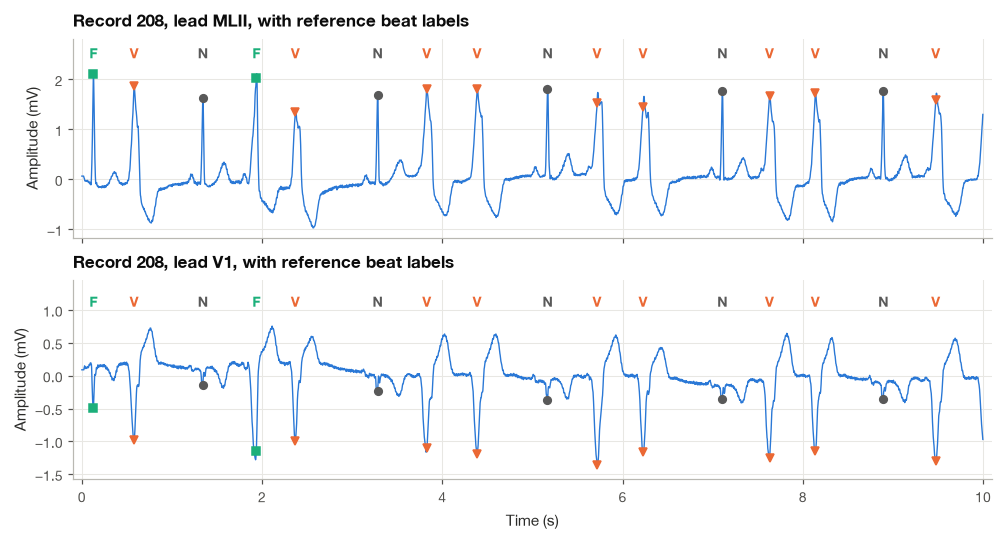

In [11]:
style = {"N": ("0.35", "o"), "V": (C[1], "v"), "F": (C[2], "s")}
fig, axes = plt.subplots(2, 1, figsize=(9, 4.8), sharex=True)
for ch, ax in enumerate(axes):
    x = rec_w.p_signal[:, ch] - np.median(rec_w.p_signal[:, ch])
    ax.plot(t_w, x, color=C[0], lw=0.9)
    top = x.max() + 0.25
    for s, sym in zip(ann_w.sample, ann_w.symbol):
        if sym not in BEAT_SYMBOLS:
            continue
        color, marker = style.get(sym, ("0.6", "x"))
        i = s - int(t0_208 * 360)
        ax.plot(s / 360, x[i], marker, color=color, ms=5)
        ax.text(s / 360, top, sym, ha="center", va="bottom", fontsize=9, color=color, fontweight="bold")
    ax.set(ylabel="Amplitude (mV)", ylim=(x.min() - 0.2, top + 0.45),
           title=f"Record 208, lead {rec_w.sig_name[ch]}, with reference beat labels")
axes[1].set_xlabel("Time (s)")
plt.show()

The ventricular beats are wide, tall in MLII and followed by a large T wave of opposite polarity, as [Section 11.1](01_cardiac_electrophysiology.ipynb) explained. The fusion beats look like a compromise between a normal beat and a PVC. Notice that a marker drawn at the annotation's sample position sits on or very near the R peak in MLII, but not necessarily at the most prominent point of the V1 trace: there is one set of annotations for both channels.

### Step 7: How precisely do the annotations mark the R peak?

Since beat annotations are often used as the "true" R-peak times, it is worth measuring where they actually sit. For every annotated beat we find the sample within ±50 ms whose deviation from the local baseline (the median from 200 to 100 ms before the annotation) is largest in absolute value, and record the offset between that sample and the annotation.

In [12]:
def annotation_offsets(record, symbol, half_window=0.05):
    """Offsets (ms) between beat annotations and the largest local deflection in channel 0."""
    x = wfdb.rdrecord(f"{DATA}/{record}", channels=[0]).p_signal[:, 0]
    ann = wfdb.rdann(f"{DATA}/{record}", "atr")
    w = int(half_window * 360)
    samples = ann.sample[(np.array(ann.symbol) == symbol) & (ann.sample > 4 * w) & (ann.sample < x.size - w)]
    offsets = [np.argmax(np.abs(x[s - w:s + w + 1] - np.median(x[s - 4 * w:s - 2 * w]))) - w for s in samples]
    return 1000 * np.array(offsets) / 360


rows, offsets_plot = [], {}
for record, symbol in [("100", "N"), ("119", "N"), ("119", "V"), ("208", "N"), ("208", "V"), ("208", "F")]:
    off = annotation_offsets(record, symbol)
    offsets_plot[(record, symbol)] = off
    rows.append([record, symbol, off.size, np.median(off), np.mean(np.abs(off) <= 2.8) * 100,
                 np.percentile(np.abs(off), 95)])
print(pd.DataFrame(rows, columns=["record", "beat", "n", "median offset (ms)", "within 1 sample (%)",
                                  "95th pct |offset| (ms)"]).round(1).to_string(index=False))

record beat    n  median offset (ms)  within 1 sample (%)  95th pct |offset| (ms)
   100    N 2238                 2.8                 97.2                     2.8
   119    N 1543                 0.0                100.0                     2.8
   119    V  444                 2.8                 58.1                     8.3
   208    N 1586                 0.0                 97.3                     2.8
   208    V  992                 8.3                 19.6                    20.7
   208    F  372                 5.6                 36.6                    23.5


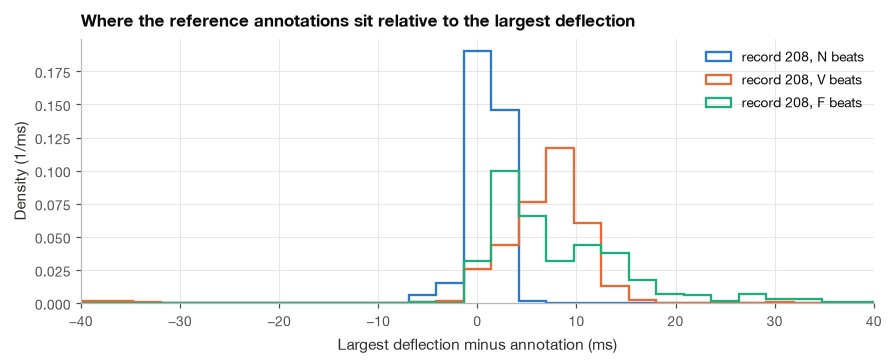

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.arange(-50, 51, 1000 / 360) - 500 / 360
for k, key in enumerate([("208", "N"), ("208", "V"), ("208", "F")]):
    ax.hist(offsets_plot[key], bins=bins, histtype="step", lw=1.5, color=C[k], density=True,
            label=f"record {key[0]}, {key[1]} beats")
ax.set(xlabel="Largest deflection minus annotation (ms)", ylabel="Density (1/ms)", xlim=(-40, 40),
       title="Where the reference annotations sit relative to the largest deflection")
ax.legend(loc="upper right")
plt.show()

For normal beats the annotation lies within one sample (2.8 ms) of the largest deflection in 97 to 100 % of beats. For ventricular and fusion beats the spread is wider, with a 95th percentile of about 20 ms in record 208, and the largest deflection tends to come later, because a wide QRS has no single sharp peak and its biggest excursion may be the late part of the complex. This is one reason the evaluation standard counts a detection as correct when it falls within 150 ms of the reference annotation {cite:p}`aami2012`, a tolerance we use in Section 19.1, and it is a warning against using reference annotations as millisecond-precise R-peak times without refining them.

(sec-11-3-5)=
## 11.3.5 The ECG Paper Grid

Clinicians read ECGs on paper, or on screens that imitate paper, and a plot drawn to the same scale is far easier to discuss with them. The standard grid has 1 mm small boxes and 5 mm large boxes, and the trace is recorded at a paper speed of 25 mm/s with a gain of 10 mm/mV {cite:p}`kligfield2007`. The calibration follows from these two numbers.

**Step 1: convert the scales to box sizes.** At 25 mm/s one millimeter corresponds to $1/25$ s, so

$$
\text{small box} = \frac{1\ \text{mm}}{25\ \text{mm/s}} = 0.04\ \text{s} = 40\ \text{ms}, \qquad
\text{large box} = 5 \times 40\ \text{ms} = 0.2\ \text{s}.
$$

At 10 mm/mV one millimeter is 0.1 mV, so a small box is 0.1 mV high and a large box 0.5 mV.

**Step 2: find the aspect ratio of the plot.** Matplotlib's `set_aspect(r)` makes one data unit on the vertical axis $r$ times as long on screen as one data unit on the horizontal axis. On paper one millivolt is 10 mm long and one second is 25 mm long, so

(eq-11-23)=
\begin{equation*}
r = \frac{10\ \text{mm/mV}}{25\ \text{mm/s}} = 0.4\ \text{s/mV}. \tag{11.23}
\end{equation*}

**Step 3: read the heart rate from the boxes.** If $n$ small boxes separate two R peaks, the RR interval is $0.04\,n$ s and the heart rate, from equation (11.9) of [Section 11.1](01_cardiac_electrophysiology.ipynb), is

(eq-11-24)=
\begin{equation*}
\mathrm{HR} = \frac{60}{0.04\,n} = \frac{1500}{n}\ \text{bpm}
\qquad\text{or, with } m \text{ large boxes,}\qquad
\mathrm{HR} = \frac{60}{0.2\,m} = \frac{300}{m}\ \text{bpm}. \tag{11.24}
\end{equation*}

This is the "300, 150, 100, 75, 60, 50" sequence that clinicians recite while counting large boxes after an R peak that falls on a heavy line.

### Step 8: Draw a two-lead strip on paper

The function below draws the grid with light lines for small boxes and darker lines for large ones, sets the aspect ratio of equation [(11.23)](#eq-11-23) and adds the standard **calibration pulse**, a 1 mV rectangle 0.2 s wide that lets the reader confirm the gain on any printout.

In [14]:
def ecg_paper(ax, t0, t1, v0, v1):
    """Standard ECG grid: 40 ms x 0.1 mV small boxes, 0.2 s x 0.5 mV large boxes, aspect (17.23)."""
    small = (np.arange(np.ceil(t0 / 0.04), np.floor(t1 / 0.04) + 1) * 0.04,
             np.arange(np.ceil(v0 / 0.1), np.floor(v1 / 0.1) + 1) * 0.1)
    for k, xg in enumerate(small[0]):
        major = round(xg / 0.04) % 5 == 0
        ax.axvline(xg, color="#e8a39b" if major else "#f8dcd8", lw=0.8 if major else 0.4, zorder=0)
    for yg in small[1]:
        major = round(yg / 0.1) % 5 == 0
        ax.axhline(yg, color="#e8a39b" if major else "#f8dcd8", lw=0.8 if major else 0.4, zorder=0)
    ax.grid(False)
    ax.set(xlim=(t0, t1), ylim=(v0, v1))
    ax.set_aspect(0.4)


def calibration_pulse(t_start, level=0.0):
    """Time and amplitude of a 1 mV, 0.2 s calibration pulse starting at t_start."""
    t = t_start + np.array([0.0, 0.04, 0.04, 0.24, 0.24, 0.32])
    v = level + np.array([0.0, 0.0, 1.0, 1.0, 0.0, 0.0])
    return t, v

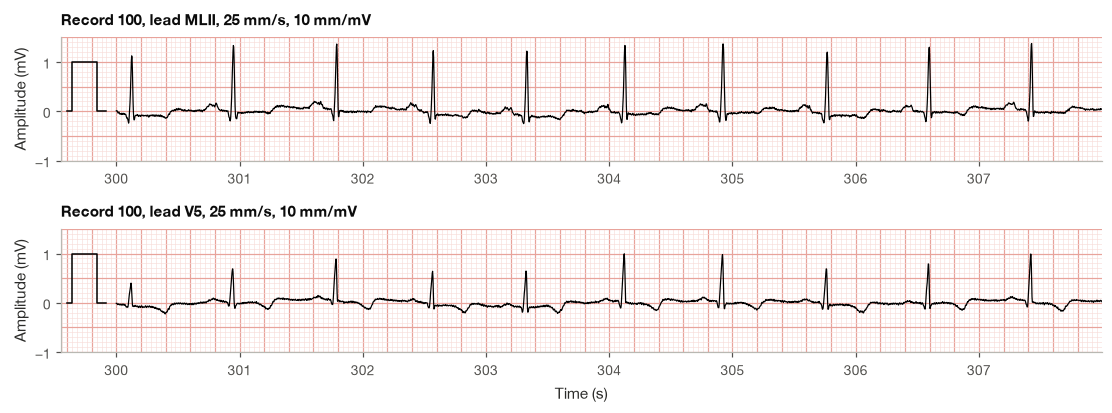

first RR interval: 0.825 s = 20.6 small boxes -> 1500 / n = 72.7 bpm


In [15]:
rec_p, ann_p, t_p = read_window("100", 300.0, 8.0)
fig, axes = plt.subplots(2, 1, figsize=(10, 3.7))
for ch, ax in enumerate(axes):
    x = rec_p.p_signal[:, ch] - np.median(rec_p.p_signal[:, ch])
    t_cal, v_cal = calibration_pulse(t_p[0] - 0.4)
    ecg_paper(ax, t_p[0] - 0.45, t_p[-1], -1.0, 1.5)
    ax.plot(t_cal, v_cal, color="k", lw=1.0)
    ax.plot(t_p, x, color="k", lw=0.8)
    ax.set_title(f"Record 100, lead {rec_p.sig_name[ch]}, 25 mm/s, 10 mm/mV", fontsize=10)
    ax.set_ylabel("Amplitude (mV)")
axes[1].set_xlabel("Time (s)")
plt.show()

beats_p = ann_p.sample[np.isin(ann_p.symbol, BEAT_SYMBOLS)] / 360
n_small = np.diff(beats_p[:2])[0] / 0.04
print(f"first RR interval: {np.diff(beats_p[:2])[0]:.3f} s = {n_small:.1f} small boxes "
      f"-> 1500 / n = {1500 / n_small:.1f} bpm")

The trace looks like a familiar rhythm strip: narrow QRS complexes two to three large boxes high in MLII, upright T waves, and a regular rhythm with a little over four large boxes between beats, which by equation [(11.24)](#eq-11-24) means a rate in the low seventies. For a printout at true scale the figure width must also be right: 10 s at 25 mm/s needs 250 mm of axis, a little under 10 inches. Diagnostic printouts sometimes use 50 mm/s or 20 mm/mV to spread out fast or small deflections, and the calibration pulse is how the reader notices.

(sec-11-3-6)=
## 11.3.6 Heart Rate over a Whole Record

### Step 9: From annotations to an instantaneous heart rate

Each pair of consecutive beats defines an RR interval $\mathrm{RR}_k = t_k - t_{k-1}$ and an **instantaneous heart rate** $\mathrm{HR}_k = 60/\mathrm{RR}_k$ (equation (11.9) again), which we assign to the time $t_k$ of the second beat. The resulting series is unevenly sampled, one value per beat, and it carries a label for each interval: an interval between two normal beats is an **NN interval**, while an interval that ends or starts at an ectopic beat reflects the timing of that ectopic beat rather than the sinus node.

In [16]:
def heart_rate_series(record):
    """Beat times (s), instantaneous heart rate (bpm) and an NN flag for every RR interval."""
    ann = wfdb.rdann(f"{DATA}/{record}", "atr")
    sym = np.array(ann.symbol)
    is_beat = np.isin(sym, BEAT_SYMBOLS)
    t_beats, labels = ann.sample[is_beat] / ann.fs, sym[is_beat]
    rr = np.diff(t_beats)
    nn = (labels[1:] == "N") & (labels[:-1] == "N")
    return t_beats[1:], 60 / rr, nn


hr_series = {r: heart_rate_series(r) for r in ["100", "119", "203"]}
for record, (t_hr, hr, nn) in hr_series.items():
    print(f"record {record}: {hr.size} RR intervals, {nn.mean():5.1%} NN, "
          f"median HR {np.median(hr):5.1f} bpm, range {hr.min():5.1f}-{hr.max():5.1f} bpm")

record 100: 2272 RR intervals, 97.0% NN, median HR  75.3 bpm, range  53.1-114.9 bpm
record 119: 1986 RR intervals, 55.3% NN, median HR  66.5 bpm, range  40.8-120.7 bpm
record 203: 2979 RR intervals, 73.9% NN, median HR  98.2 bpm, range  32.4-240.0 bpm


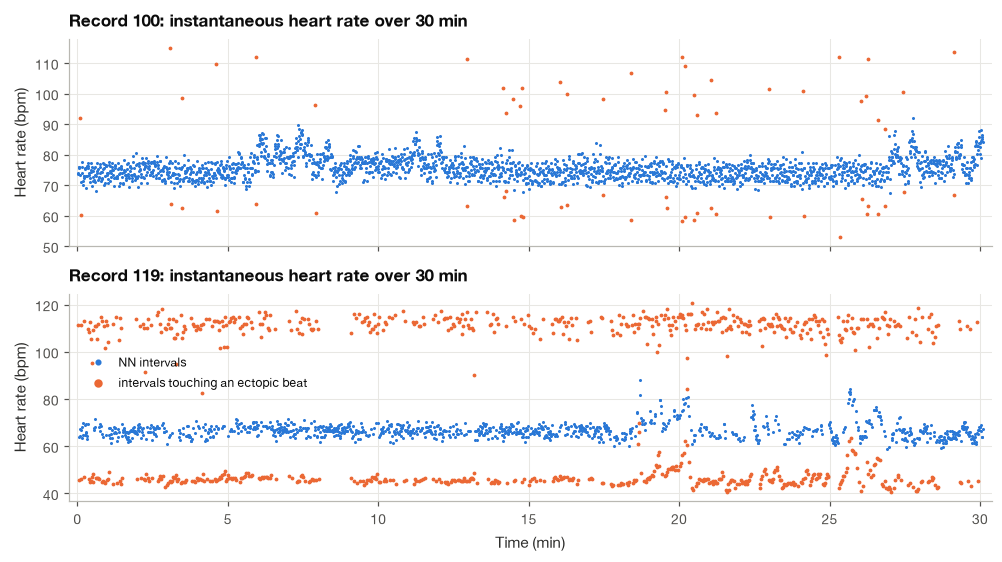

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.0), sharex=True)
for ax, record in zip(axes, ["100", "119"]):
    t_hr, hr, nn = hr_series[record]
    ax.plot(t_hr[nn] / 60, hr[nn], ".", color=C[0], ms=2, label="NN intervals")
    ax.plot(t_hr[~nn] / 60, hr[~nn], ".", color=C[1], ms=3, label="intervals touching an ectopic beat")
    ax.set(ylabel="Heart rate (bpm)", title=f"Record {record}: instantaneous heart rate over 30 min")
axes[1].legend(loc="center left", bbox_to_anchor=(0.01, 0.62), markerscale=3, fontsize=8)
axes[1].set_xlabel("Time (min)")
plt.show()

In record 100 the NN heart rate drifts slowly between about 70 and 85 bpm, and the few orange points are the atrial premature beats, each producing one fast value (the short coupling interval) followed by one slow value (the pause after it). Record 119 looks very different: during its bigeminy episodes every second beat is a PVC, so the instantaneous rate alternates between two bands, one above 100 bpm and one below 60 bpm, while the sinus rate underneath, visible in the blue NN points, stays between them. The figure is a good argument for always separating NN intervals from the others before computing heart rate variability, as Section 19.2 does.

### Step 10: Two ways to average the heart rate

"The mean heart rate" sounds unambiguous, but there are two natural estimates: the mean of the instantaneous rates, $\overline{60/\mathrm{RR}}$, and the rate that corresponds to the mean interval, $60/\overline{\mathrm{RR}}$. They differ, and the difference grows with the irregularity of the rhythm. To see by how much, treat the RR interval as a random variable with mean $\mu$ and standard deviation $\sigma$, and expand $g(r) = 60/r$ in a Taylor series around $\mu$:

$$
g(r) \approx g(\mu) + g'(\mu)\,(r - \mu) + \tfrac{1}{2}\,g''(\mu)\,(r - \mu)^2,
\qquad g'(\mu) = -\frac{60}{\mu^2}, \quad g''(\mu) = \frac{120}{\mu^3}.
$$

Taking the expectation, the linear term vanishes because $\mathbb{E}[r - \mu] = 0$, and the quadratic term becomes $\sigma^2$:

(eq-11-25)=
\begin{equation*}
\mathbb{E}\!\left[\frac{60}{\mathrm{RR}}\right] \approx \frac{60}{\mu} + \frac{1}{2}\cdot\frac{120}{\mu^3}\,\sigma^2
= \frac{60}{\mu}\left(1 + \frac{\sigma^2}{\mu^2}\right). \tag{11.25}
\end{equation*}

The mean of the instantaneous rates exceeds $60/\mu$ by a fraction equal to the squared coefficient of variation of the RR intervals. Because $60/r$ is convex, the inequality $\overline{60/\mathrm{RR}} \ge 60/\overline{\mathrm{RR}}$ holds exactly (it is Jensen's inequality); equation [(11.25)](#eq-11-25) tells us its size. For a regular sinus rhythm with a coefficient of variation of 5 % the difference is a quarter of a percent. In atrial fibrillation, where the coefficient of variation can exceed 30 %, it is around 10 %.

In [18]:
rows = []
for record in ["100", "119", "203"]:
    t_hr, hr, nn = hr_series[record]
    rr = 60 / hr
    mu, cv = rr.mean(), rr.std() / rr.mean()
    rows.append([record, cv, hr.mean(), 60 / mu, 60 / mu * (1 + cv ** 2)])
print(pd.DataFrame(rows, columns=["record", "CV of RR", "mean of 60/RR (bpm)", "60/mean RR (bpm)",
                                  "prediction (17.25) (bpm)"]).round(3).to_string(index=False))

record  CV of RR  mean of 60/RR (bpm)  60/mean RR (bpm)  prediction (17.25) (bpm)
   100     0.061               75.817            75.510                    75.796
   119     0.284               72.196            66.049                    71.380
   203     0.330              110.645            99.044                   109.860


The second-order prediction matches the mean of the instantaneous rates within about one beat per minute even for record 203, where the two averages differ by more than 11 bpm. Neither average is wrong; they answer different questions. The number of beats in a minute equals $60/\overline{\mathrm{RR}}$, which is what a clinician counting beats would report, so that is the definition I use for "mean heart rate" in this book.

### Step 11: Rhythm episodes and heart rate together

Record 203 combines both themes of this section. We draw its rhythm episodes from Step 5 as a colored bar above the instantaneous heart rate.

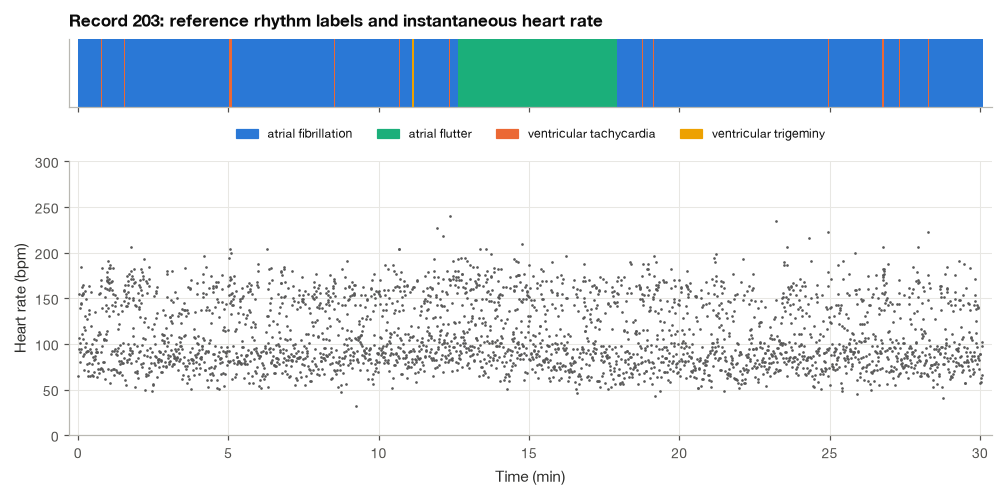

In [19]:
rhythm_colors = {"(AFIB": C[0], "(AFL": C[2], "(VT": C[1], "(T": C[3]}
fig, axes = plt.subplots(2, 1, figsize=(9, 4.4), sharex=True, gridspec_kw={"height_ratios": [0.5, 2]})
for _, ep in episodes203.iterrows():
    axes[0].axvspan(ep["start (s)"] / 60, ep["end (s)"] / 60, color=rhythm_colors[ep["rhythm"]], lw=0)
axes[0].set(yticks=[], title="Record 203: reference rhythm labels and instantaneous heart rate")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in rhythm_colors.values()]
axes[0].legend(handles, [RHYTHMS[r] for r in rhythm_colors], loc="upper center", ncol=4, fontsize=8,
               bbox_to_anchor=(0.5, -0.15), frameon=False)
t_hr, hr, nn = hr_series["203"]
axes[1].plot(t_hr / 60, hr, ".", color="0.35", ms=1.5)
axes[1].set(xlabel="Time (min)", ylabel="Heart rate (bpm)", ylim=(0, 300))
plt.show()

During atrial fibrillation the instantaneous rate scatters over a wide band, roughly 50 to 200 bpm, which is the "irregularly irregular" ventricular response seen from the RR side. The ventricular tachycardia runs, only a few beats each, are hard to pick out of the scatter at all, a reminder that the rhythm labels carry information that the RR series alone does not. Turning these visual impressions into numbers, such as the dispersion of successive RR intervals within a window, is exactly how the atrial fibrillation detector of Section 19.4 works.

(sec-11-3-7)=
## 11.3.7 Getting Data In and Out

### Step 12: A one-line inventory of every record

With the helpers above we can describe the six records used throughout Part V in a single table: duration, leads, number of beats in each AAMI class and mean heart rate.

In [20]:
rows = []
for record in RECORDS:
    h = wfdb.rdheader(f"{DATA}/{record}")
    a = wfdb.rdann(f"{DATA}/{record}", "atr")
    beats = [s for s in a.symbol if s in AAMI]
    classes = pd.Series([AAMI[s] for s in beats]).value_counts()
    t_beats = a.sample[np.isin(a.symbol, BEAT_SYMBOLS)] / h.fs
    rows.append({"record": record, "minutes": h.sig_len / h.fs / 60, "leads": "/".join(h.sig_name),
                 **{c: classes.get(c, 0) for c in "NSVFQ"}, "mean HR (bpm)": 60 / np.mean(np.diff(t_beats))})
inventory = pd.DataFrame(rows).set_index("record")
print(inventory.round(1).to_string())

        minutes    leads     N   S    V    F  Q  mean HR (bpm)
record                                                        
100        30.1  MLII/V5  2239  33    1    0  0           75.5
105        30.1  MLII/V1  2526   0   41    0  5           85.5
106        30.1  MLII/V1  1507   0  520    0  0           67.4
119        30.1  MLII/V1  1543   0  444    0  0           66.0
203        30.1  MLII/V1  2529   2  444    1  4           99.0
208        30.1  MLII/V1  1586   2  992  373  2           98.2


### Step 13: Streaming records from PhysioNet

The records used in this book are stored locally so that every notebook runs offline. The same functions can read any PhysioNet database directly over the internet through the `pn_dir` argument, or download whole databases. The code below, shown for reference and not executed when the book is built, reads the first 10 s of record 101 straight from the PhysioNet server, then lists the records of the database and downloads the first five.

```python
import wfdb

rec = wfdb.rdrecord("101", pn_dir="mitdb", sampto=3600)
ann = wfdb.rdann("101", "atr", pn_dir="mitdb", sampto=3600)

records = wfdb.get_record_list("mitdb")
wfdb.dl_database("mitdb", dl_dir="data/mitdb", records=records[:5])
```

Downloading once and reading locally is kinder to the server and much faster when a notebook is run repeatedly.

### Step 14: Export to CSV and NumPy files

Other software, or a colleague without `wfdb`, may need the data in a plain format. A CSV file is universal and human-readable; a compressed NumPy `.npz` archive is compact and keeps data types exact. We export five minutes of record 100 both ways, together with the beat annotations, read the files back and compare sizes. The files go to a temporary directory so that building the book leaves nothing behind.

In [21]:
rec5 = wfdb.rdrecord(f"{DATA}/100", sampto=5 * 60 * 360)
ann5 = wfdb.rdann(f"{DATA}/100", "atr", sampto=5 * 60 * 360)
signals = pd.DataFrame(rec5.p_signal, columns=rec5.sig_name)
signals.insert(0, "time_s", np.arange(rec5.sig_len) / rec5.fs)
beats5 = pd.DataFrame({"sample": ann5.sample, "symbol": ann5.symbol})

with tempfile.TemporaryDirectory() as tmp:
    signals.to_csv(f"{tmp}/rec100.csv", index=False, float_format="%.3f")
    beats5.to_csv(f"{tmp}/rec100_beats.csv", index=False)
    np.savez_compressed(f"{tmp}/rec100.npz", signal_adu=rec5.adc(), fs=rec5.fs, gain=rec5.adc_gain,
                        baseline=rec5.baseline, sig_name=rec5.sig_name,
                        ann_sample=ann5.sample, ann_symbol=ann5.symbol)
    sizes = {name: os.path.getsize(f"{tmp}/{name}") / 1e3 for name in ["rec100.csv", "rec100.npz"]}
    back_csv = pd.read_csv(f"{tmp}/rec100.csv")
    with np.load(f"{tmp}/rec100.npz") as npz:
        back_npz = (npz["signal_adu"] - npz["baseline"]) / npz["gain"]          # equation (17.21)
        same_symbols = np.array_equal(npz["ann_symbol"], ann5.symbol)

print(f"CSV : {sizes['rec100.csv']:7.1f} kB, max error {np.abs(back_csv[rec5.sig_name].values - rec5.p_signal).max():.1e} mV")
print(f"NPZ : {sizes['rec100.npz']:7.1f} kB, max error {np.abs(back_npz - rec5.p_signal).max():.1e} mV, "
      f"annotations intact: {same_symbols}")
print(f"format 212 would need {3 * rec5.sig_len * 2 / 2 / 1e3:.1f} kB")

CSV :  2330.1 kB, max error 0.0e+00 mV
NPZ :   242.3 kB, max error 0.0e+00 mV, annotations intact: True
format 212 would need 324.0 kB


The `.npz` file stores the original integers together with the gain and baseline, so equation [(11.21)](#eq-11-21) reproduces the physical signal exactly; the CSV stores rounded decimal text, which is lossless here only because three decimals are enough for a 5 µV resolution, and it is almost ten times larger. The compressed `.npz` file is even smaller than the packed format 212 would be, because ECG samples change slowly and compress well. I prefer to keep integers plus calibration whenever I archive biomedical data, because it records the true resolution of the measurement instead of an arbitrary number of printed digits. If the recipient uses WFDB tools, `wfdb.wrsamp` writes a proper header and signal file, and `wfdb.wrann` writes annotations.

## Summary

A PhysioNet record is a text header, a binary signal file and one or more annotation files. The header gives the sampling rate, the storage format and, for each signal, the gain and baseline that convert stored integers to millivolts through $x = (d - b)/G$. We decoded format 212, two 12-bit values packed into three bytes, directly with NumPy bit operations and confirmed every value and both checksums against the `wfdb` reader. Annotations are labeled time points; beat labels must be selected by an explicit list of symbols, rhythm changes are `+` annotations whose rhythm is in `aux_note`, and the standard AAMI grouping maps the beat labels to the five classes N, S, V, F and Q. Reference beat annotations sit within one sample of the largest deflection for normal beats but are less precise for wide ventricular beats. We drew the ECG on the standard 25 mm/s, 10 mm/mV grid by setting an aspect ratio of 0.4 s/mV, derived the 1500/$n$ and 300/$m$ rules for reading heart rate from the boxes, and showed that the mean of the instantaneous heart rate exceeds $60/\overline{\mathrm{RR}}$ by the squared coefficient of variation, more than 11 bpm in atrial fibrillation.

These tools carry us through the rest of Part V. [Chapter 12](../ch18_ecg_preprocessing/index.md) uses the same reading functions to add real noise to clean records and remove it again, and Chapter 19 uses the beat annotations as the reference for QRS detection, the NN intervals for heart rate variability, the beat classes for morphology and the rhythm episodes for atrial fibrillation detection.

## Exercises

1. The first three bytes of `105.dat` can be read with `np.fromfile(..., count=3)`. Decode the first sample of each channel by hand with equation (11.22), convert both to millivolts with equation (11.21) using the gains and baselines in `105.hea`, and check your answers against `wfdb.rdrecord`.
2. An ECG is printed at 50 mm/s and 20 mm/mV. What time and voltage does one small box represent, what aspect ratio must a plot use, and how does the 1500/$n$ heart-rate rule change? A heart rate is reported as 150 bpm from a printout whose speed setting was overlooked; what is the true rate if the paper actually ran at 50 mm/s?
3. Equation (11.25) is a second-order approximation. Show that the exact mean of $60/\mathrm{RR}$ for RR intervals uniformly distributed on $[\mu - a, \mu + a]$ is $\frac{30}{a}\ln\frac{\mu + a}{\mu - a}$, and compare it numerically with equation (11.25) for $\mu = 0.8$ s and $a$ from 0.05 to 0.4 s.
4. For record 105, use the `~` annotations and their `subtype` values to compute the total time during which each channel is marked as noisy, and plot the MLII signal for a 10 s window around the longest noisy episode. Do the isolated artifact annotations `|` cluster in the noisy periods?
5. Using `rhythm_episodes`, find the bigeminy episodes of records 106 and 119. Compute the median NN heart rate inside and outside these episodes, and the median coupling interval of the PVCs. Discuss whether the sinus rate changes during bigeminy.
6. (Harder.) MIT-format annotation files store each annotation as a little-endian 16-bit word whose top 6 bits are the annotation code and bottom 10 bits the number of samples since the previous annotation, with special codes for longer intervals (59, followed by a 32-bit interval) and for auxiliary text (63, with the text length in the 10-bit field, followed by the bytes, padded to an even length). Write a decoder for `100.atr` that recovers the sample positions and numeric codes, and check the positions against `wfdb.rdann`. The PhysioNet documentation of the annotation format gives the remaining details.

## Further Reading

{cite:t}`moody2001` tell the history of the MIT-BIH Arrhythmia Database, how the recordings were selected and digitized and how the reference annotations were produced, and {cite:t}`goldberger2000` describe PhysioNet and the WFDB software that defines the file formats used here. The AAMI standard {cite:p}`aami2012` defines the beat classes and the evaluation rules that most arrhythmia studies follow, and {cite:t}`dechazal2004` show how the MIT-BIH labels are mapped to those classes in a classification study. The standard paper speed, gain and calibration conventions are part of the recommendations of {cite:t}`kligfield2007`.